<a href="https://colab.research.google.com/github/sriharithamanikandan/google-play-store-analysis/blob/main/Google_Play_Store_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn textblob plotly openpyxl

In [2]:
from google.colab import files

uploaded = files.upload()

Saving googleplaystore.csv to googleplaystore.csv
Saving googleplaystore_user_reviews.csv to googleplaystore_user_reviews.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from textblob import TextBlob

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
apps = pd.read_csv("googleplaystore.csv")

print("Apps Dataset Loaded Successfully!")
print("Shape:", apps.shape)

apps.head()

Apps Dataset Loaded Successfully!
Shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [5]:
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

print("User Reviews Dataset Loaded Successfully!")
print("Shape:", reviews.shape)

reviews.head()

User Reviews Dataset Loaded Successfully!
Shape: (64295, 5)


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [6]:
print("Apps Dataset Columns:")
print(apps.columns.tolist())

print("\nReviews Dataset Columns:")
print(reviews.columns.tolist())

Apps Dataset Columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Reviews Dataset Columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [7]:
print("===== APPS DATASET =====")

apps.info()

print("\n===== REVIEWS DATASET =====")

reviews.info()

===== APPS DATASET =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB

===== REVIEWS DATASET =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 

In [8]:
print("Missing Values in Apps Dataset:")
print(apps.isnull().sum())

print("\nMissing Values in Reviews Dataset:")
print(reviews.isnull().sum())

Missing Values in Apps Dataset:
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

Missing Values in Reviews Dataset:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


In [ ]:
print("Duplicate rows in Apps:", apps.duplicated().sum())

print("Duplicate rows in Reviews:", reviews.duplicated().sum())

In [9]:
apps = apps.drop_duplicates().copy()

apps["App"] = apps["App"].astype("string").str.strip()

apps["Category"] = (
    apps["Category"]
    .astype("string")
    .str.strip()
)

print("Duplicate rows removed.")
print("Current shape:", apps.shape)

Duplicate rows removed.
Current shape: (10358, 13)


In [10]:
apps["Rating"] = pd.to_numeric(
    apps["Rating"],
    errors="coerce"
)

apps.loc[
    ~apps["Rating"].between(0, 5),
    "Rating"
] = np.nan

print("Rating column cleaned.")
print(apps["Rating"].describe())

Rating column cleaned.
count    8892.000000
mean        4.187877
std         0.522377
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64


In [11]:
apps["Installs"] = (
    apps["Installs"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

apps["Installs"] = pd.to_numeric(
    apps["Installs"],
    errors="coerce"
)

print(apps[["App", "Installs"]].head(10))

                                                 App  Installs
0     Photo Editor & Candy Camera & Grid & ScrapBook     10000
1                                Coloring book moana    500000
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   5000000
3                              Sketch - Draw & Paint  50000000
4              Pixel Draw - Number Art Coloring Book    100000
5                         Paper flowers instructions     50000
6            Smoke Effect Photo Maker - Smoke Editor     50000
7                                   Infinite Painter   1000000
8                               Garden Coloring Book   1000000
9                      Kids Paint Free - Drawing Fun     10000


In [12]:
apps["Price"] = (
    apps["Price"]
    .astype("string")
    .str.replace("$", "", regex=False)
)

apps["Price"] = pd.to_numeric(
    apps["Price"],
    errors="coerce"
)

print(apps[["App", "Price"]].head(10))

                                                 App  Price
0     Photo Editor & Candy Camera & Grid & ScrapBook    0.0
1                                Coloring book moana    0.0
2  U Launcher Lite – FREE Live Cool Themes, Hide ...    0.0
3                              Sketch - Draw & Paint    0.0
4              Pixel Draw - Number Art Coloring Book    0.0
5                         Paper flowers instructions    0.0
6            Smoke Effect Photo Maker - Smoke Editor    0.0
7                                   Infinite Painter    0.0
8                               Garden Coloring Book    0.0
9                      Kids Paint Free - Drawing Fun    0.0


In [13]:
def convert_size(size):
    if pd.isna(size):
        return np.nan

    size = str(size).strip()

    if size == "Varies with device":
        return np.nan

    try:
        if size.endswith("M"):
            return float(size[:-1])

        elif size.endswith("k"):
            return float(size[:-1]) / 1024

        else:
            return np.nan

    except ValueError:
        return np.nan


apps["Size_MB"] = apps["Size"].apply(convert_size)

print(apps[["App", "Size", "Size_MB"]].head(15))

                                                  App  Size  Size_MB
0      Photo Editor & Candy Camera & Grid & ScrapBook   19M     19.0
1                                 Coloring book moana   14M     14.0
2   U Launcher Lite – FREE Live Cool Themes, Hide ...  8.7M      8.7
3                               Sketch - Draw & Paint   25M     25.0
4               Pixel Draw - Number Art Coloring Book  2.8M      2.8
5                          Paper flowers instructions  5.6M      5.6
6             Smoke Effect Photo Maker - Smoke Editor   19M     19.0
7                                    Infinite Painter   29M     29.0
8                                Garden Coloring Book   33M     33.0
9                       Kids Paint Free - Drawing Fun  3.1M      3.1
10                            Text on Photo - Fonteee   28M     28.0
11            Name Art Photo Editor - Focus n Filters   12M     12.0
12                     Tattoo Name On My Photo Editor   20M     20.0
13                              Ma

In [14]:
apps["Type"] = (
    apps["Type"]
    .astype("string")
    .str.strip()
    .str.title()
)

apps["Category"] = (
    apps["Category"]
    .astype("string")
    .str.strip()
    .str.upper()
)

print(apps["Type"].value_counts(dropna=False))
print("\nTop categories:")
print(apps["Category"].value_counts().head(10))

Type
Free    9591
Paid     765
<NA>       1
0          1
Name: count, dtype: Int64

Top categories:
Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: Int64


In [15]:
apps = apps.dropna(
    subset=["App", "Category"]
).copy()

apps = apps[
    apps["Installs"].notna()
    & apps["Price"].notna()
].copy()

apps = apps[
    (apps["Installs"] >= 0)
    & (apps["Price"] >= 0)
].copy()

print("Cleaned Apps Dataset Shape:", apps.shape)

apps.head()

Cleaned Apps Dataset Shape: (10357, 14)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,19.0
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,500000,Free,0.0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up,14.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,8.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,25.0
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,2.8


In [16]:
category_counts = apps["Category"].value_counts()

print("Top 10 Categories:")
print(category_counts.head(10))

Top 10 Categories:
Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: Int64


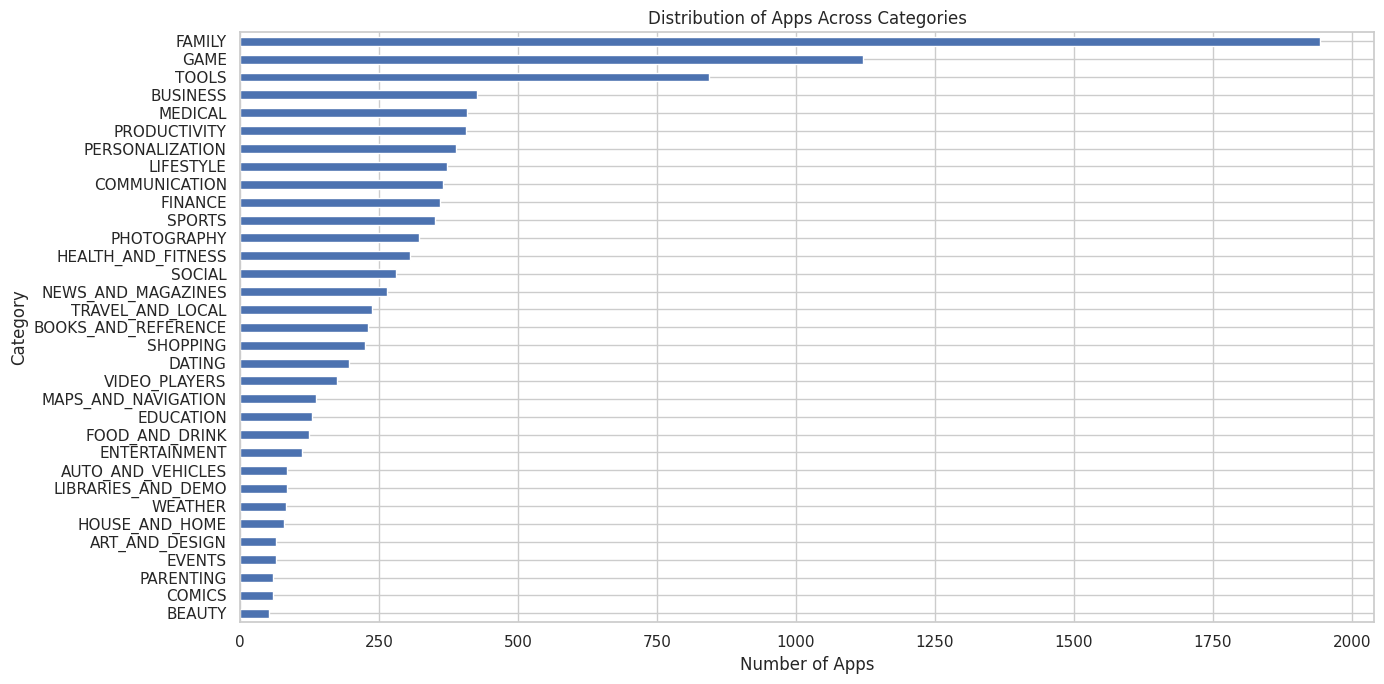

In [17]:
plt.figure(figsize=(14, 7))

category_counts.sort_values().plot(
    kind="barh"
)

plt.title("Distribution of Apps Across Categories")
plt.xlabel("Number of Apps")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

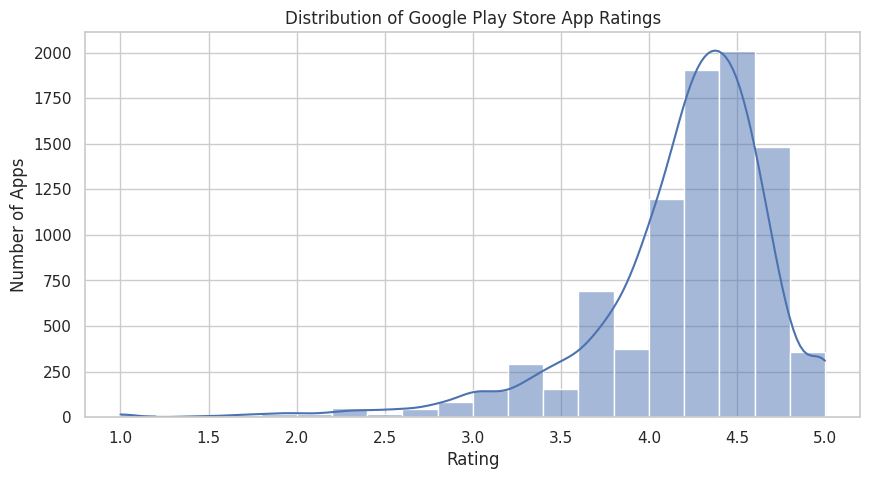

In [18]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=apps,
    x="Rating",
    bins=20,
    kde=True
)

plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")

plt.show()

In [19]:
avg_rating = (
    apps.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Rating by Category:")
print(avg_rating.round(2))

Average Rating by Category:
Category
EVENTS                 4.44
EDUCATION              4.38
ART_AND_DESIGN         4.36
BOOKS_AND_REFERENCE    4.35
PERSONALIZATION        4.33
PARENTING              4.30
GAME                   4.28
BEAUTY                 4.28
HEALTH_AND_FITNESS     4.26
SOCIAL                 4.25
SHOPPING               4.25
WEATHER                4.24
SPORTS                 4.23
PRODUCTIVITY           4.20
FAMILY                 4.19
AUTO_AND_VEHICLES      4.19
PHOTOGRAPHY            4.18
MEDICAL                4.18
LIBRARIES_AND_DEMO     4.18
HOUSE_AND_HOME         4.16
FOOD_AND_DRINK         4.16
COMICS                 4.16
COMMUNICATION          4.15
ENTERTAINMENT          4.14
NEWS_AND_MAGAZINES     4.13
FINANCE                4.13
BUSINESS               4.10
LIFESTYLE              4.10
TRAVEL_AND_LOCAL       4.09
VIDEO_PLAYERS          4.06
MAPS_AND_NAVIGATION    4.05
TOOLS                  4.05
DATING                 3.97
Name: Rating, dtype: float64


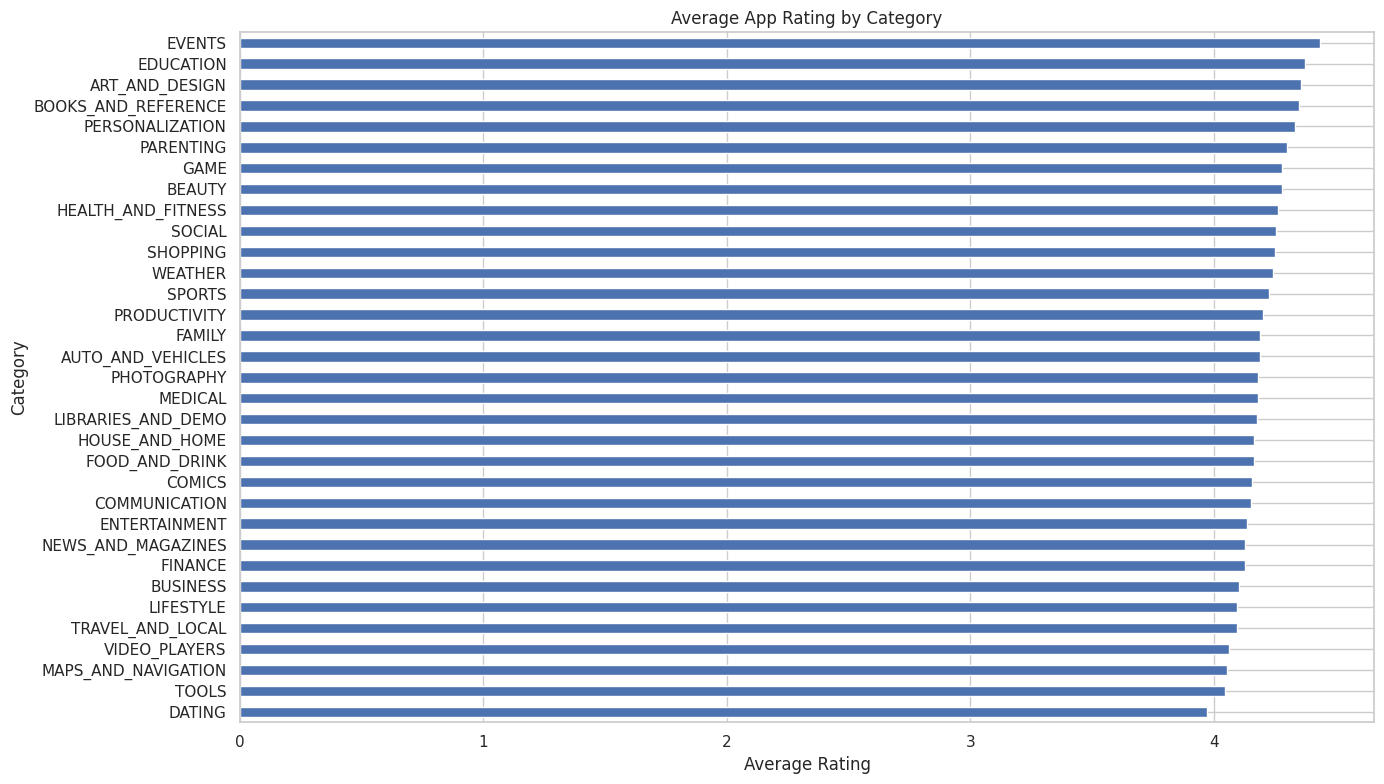

In [20]:
plt.figure(figsize=(14, 8))

avg_rating.sort_values().plot(
    kind="barh"
)

plt.title("Average App Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

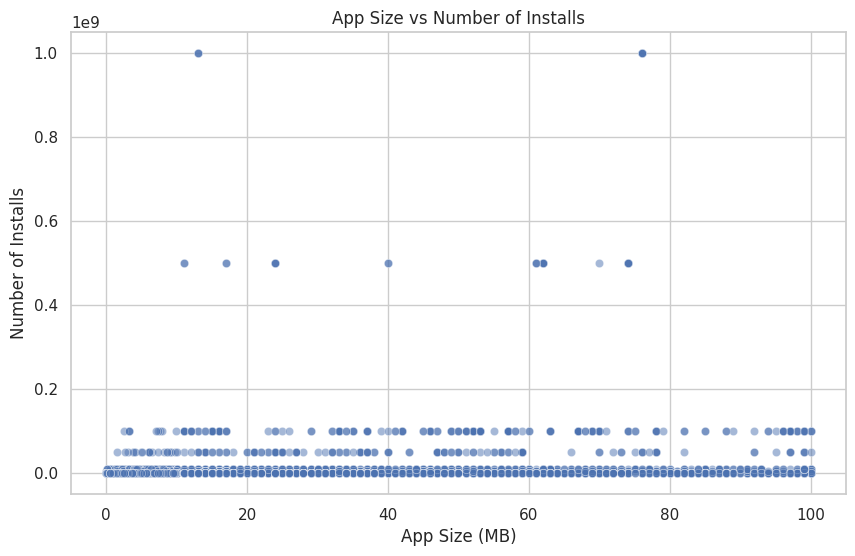

In [21]:
size_data = apps.dropna(
    subset=["Size_MB", "Installs"]
).copy()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=size_data,
    x="Size_MB",
    y="Installs",
    alpha=0.5
)

plt.title("App Size vs Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs")

plt.show()

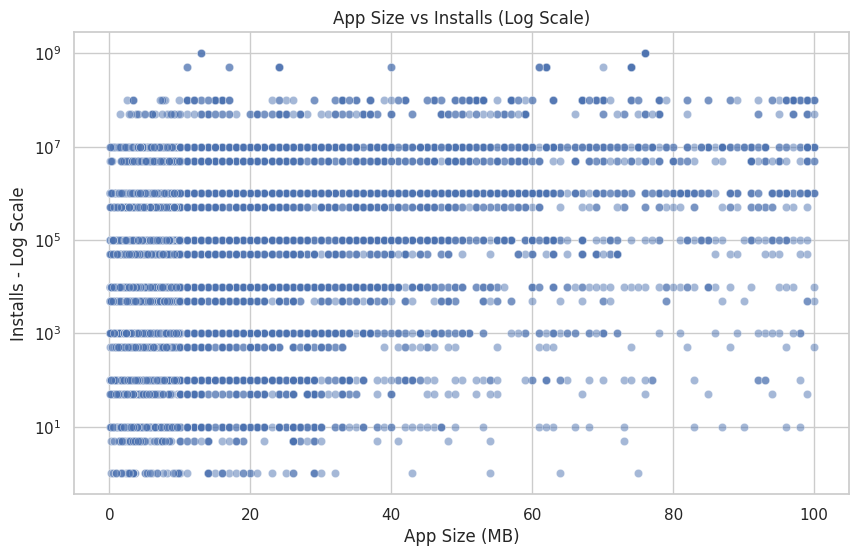

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=size_data,
    x="Size_MB",
    y="Installs",
    alpha=0.5
)

plt.yscale("log")

plt.title("App Size vs Installs (Log Scale)")
plt.xlabel("App Size (MB)")
plt.ylabel("Installs - Log Scale")

plt.show()

In [23]:
correlation = size_data[
    ["Size_MB", "Installs"]
].corr(method="spearman").iloc[0, 1]

print("Spearman Correlation:", round(correlation, 4))

Spearman Correlation: 0.342


In [24]:
apps["App_Type"] = np.where(
    apps["Price"] == 0,
    "Free",
    "Paid"
)

type_counts = apps["App_Type"].value_counts()

print(type_counts)

App_Type
Free    9592
Paid     765
Name: count, dtype: int64


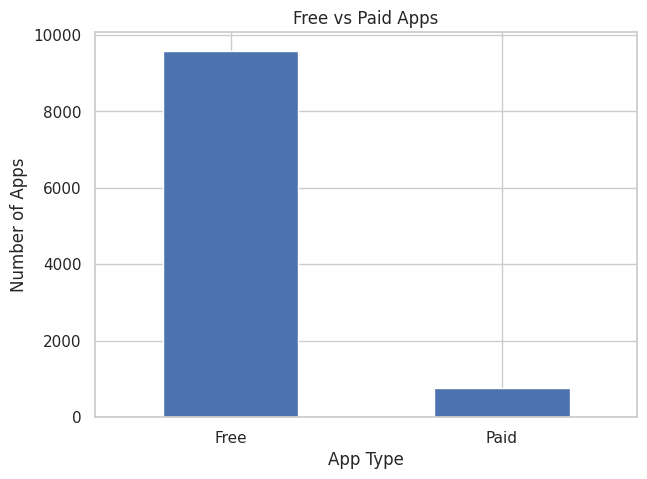

In [25]:
plt.figure(figsize=(7, 5))

type_counts.plot(
    kind="bar"
)

plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")

plt.xticks(rotation=0)
plt.show()

In [26]:
paid_apps = apps[
    apps["Price"] > 0
].copy()

print("Number of Paid Apps:", len(paid_apps))
print(paid_apps["Price"].describe())

Number of Paid Apps: 765
count        765.0
mean     13.955556
std      58.406966
min           0.99
25%           1.49
50%           2.99
75%           4.99
max          400.0
Name: Price, dtype: Float64


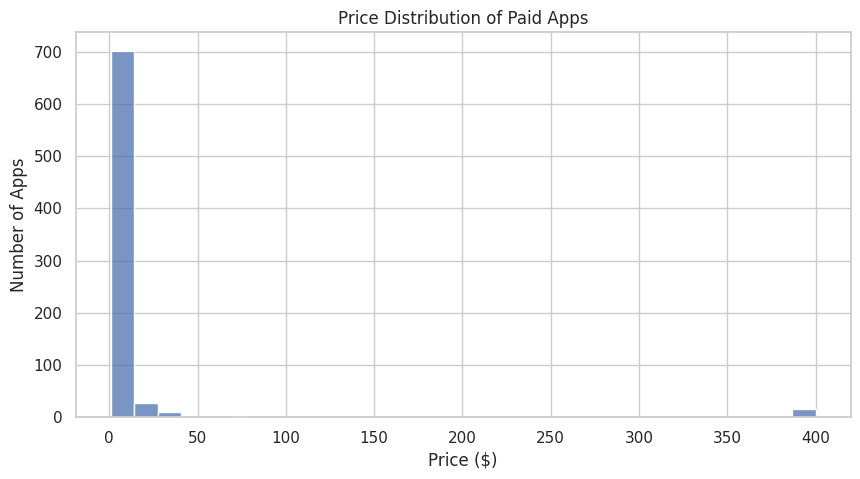

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=paid_apps,
    x="Price",
    bins=30
)

plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")

plt.show()

In [28]:
apps["Estimated_Revenue"] = (
    apps["Price"] * apps["Installs"]
)

revenue_by_category = (
    apps.groupby("Category")["Estimated_Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Estimated Revenue by Category:")
print(revenue_by_category.head(15).round(2))

Estimated Revenue by Category:
Category
FAMILY                 185780335.36
LIFESTYLE                57583939.4
GAME                    40987636.85
FINANCE                 25726678.98
PHOTOGRAPHY               8942767.7
MEDICAL                  8456535.67
PERSONALIZATION          7786947.56
TOOLS                    5464820.59
SPORTS                   4706211.95
PRODUCTIVITY             4313374.95
COMMUNICATION             4247364.5
WEATHER                   4181380.0
EDUCATION                 2403980.0
HEALTH_AND_FITNESS        1426068.9
MAPS_AND_NAVIGATION       1240789.0
Name: Estimated_Revenue, dtype: Float64


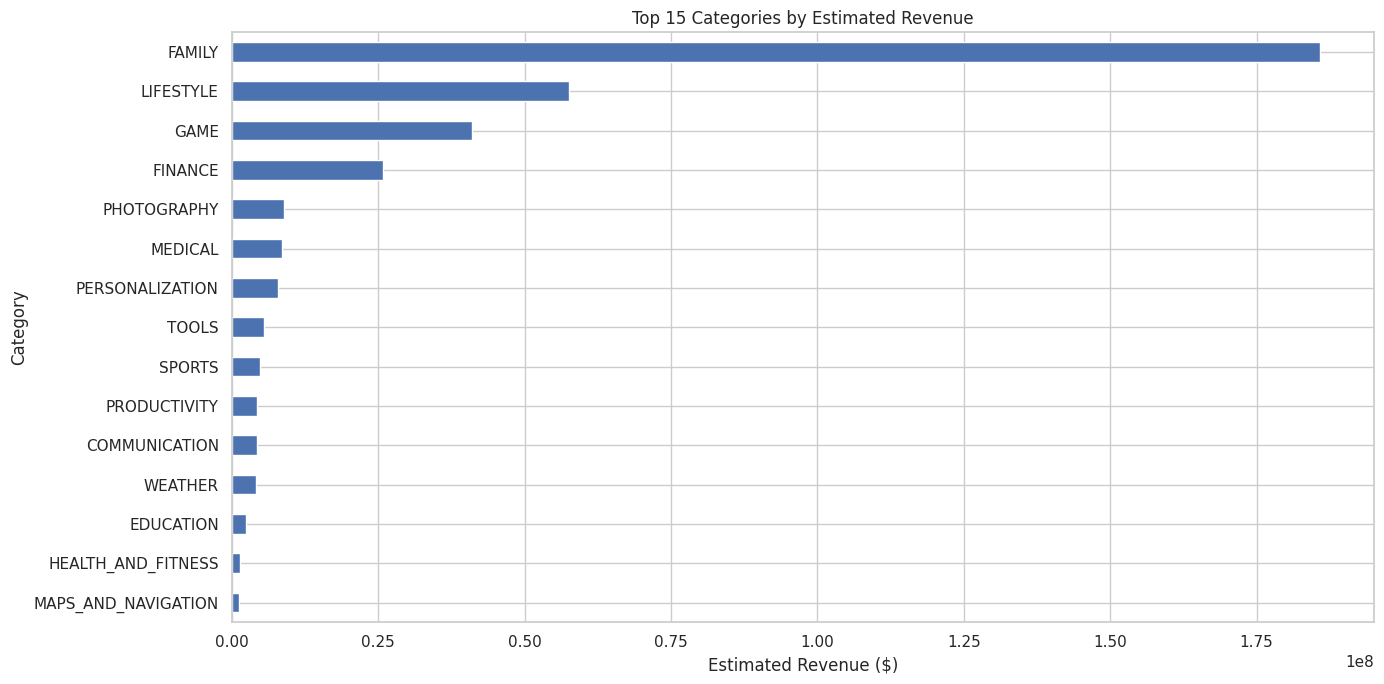

In [29]:
plt.figure(figsize=(14, 7))

revenue_by_category.head(15).sort_values().plot(
    kind="barh"
)

plt.title("Top 15 Categories by Estimated Revenue")
plt.xlabel("Estimated Revenue ($)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [30]:
print("Reviews Shape:", reviews.shape)

print("\nMissing Values:")
print(reviews.isnull().sum())

reviews.head()

Reviews Shape: (64295, 5)

Missing Values:
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [31]:
reviews = reviews.drop_duplicates().copy()

reviews = reviews.dropna(
    subset=["Translated_Review"]
).copy()

reviews["Translated_Review"] = (
    reviews["Translated_Review"]
    .astype(str)
    .str.strip()
)

reviews = reviews[
    reviews["Translated_Review"] != ""
].copy()

print("Cleaned Reviews Shape:", reviews.shape)

reviews.head()

Cleaned Reviews Shape: (29692, 5)


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
5,10 Best Foods for You,Best way,Positive,1.00,0.300000


In [32]:
def get_polarity(text):
    return TextBlob(str(text)).sentiment.polarity


reviews["Calculated_Polarity"] = (
    reviews["Translated_Review"]
    .apply(get_polarity)
)

print(
    reviews[
        ["Translated_Review", "Calculated_Polarity"]
    ].head(10)
)

                                    Translated_Review  Calculated_Polarity
0   I like eat delicious food. That's I'm cooking ...                 1.00
1     This help eating healthy exercise regular basis                 0.25
3          Works great especially going grocery store                 0.40
4                                        Best idea us                 1.00
5                                            Best way                 1.00
6                                             Amazing                 0.60
8                                Looking forward app,                 0.00
9               It helpful site ! It help foods get !                 0.00
10                                          good you.                 0.70
11  Useful information The amount spelling errors ...                 0.20


In [33]:
def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"


reviews["Calculated_Sentiment"] = (
    reviews["Calculated_Polarity"]
    .apply(classify_sentiment)
)

print(
    reviews[
        [
            "Translated_Review",
            "Calculated_Polarity",
            "Calculated_Sentiment"
        ]
    ].head(15)
)

                                    Translated_Review  Calculated_Polarity  \
0   I like eat delicious food. That's I'm cooking ...             1.000000   
1     This help eating healthy exercise regular basis             0.250000   
3          Works great especially going grocery store             0.400000   
4                                        Best idea us             1.000000   
5                                            Best way             1.000000   
6                                             Amazing             0.600000   
8                                Looking forward app,             0.000000   
9               It helpful site ! It help foods get !             0.000000   
10                                          good you.             0.700000   
11  Useful information The amount spelling errors ...             0.200000   
12  Thank you! Great app!! Add arthritis, eyes, im...             0.750000   
13  Greatest ever Completely awesome maintain heal...           

In [34]:
sentiment_counts = (
    reviews["Calculated_Sentiment"]
    .value_counts()
)

print("Sentiment Distribution:")
print(sentiment_counts)

Sentiment Distribution:
Calculated_Sentiment
Positive    19014
Negative     6322
Neutral      4356
Name: count, dtype: int64


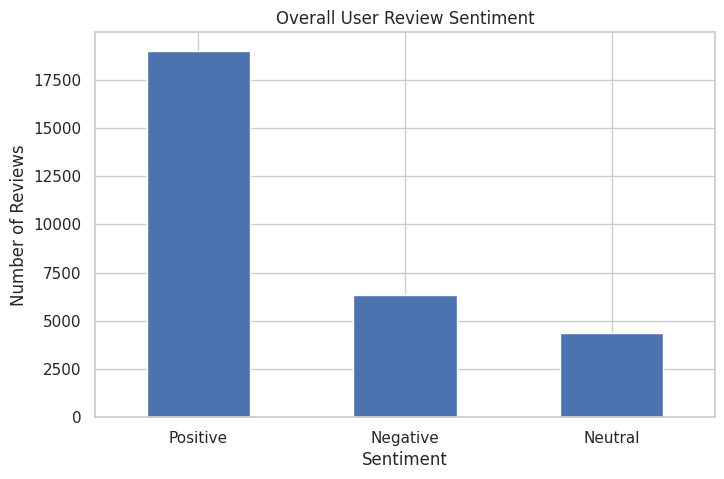

In [35]:
plt.figure(figsize=(8, 5))

sentiment_counts.plot(
    kind="bar"
)

plt.title("Overall User Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.xticks(rotation=0)
plt.show()

In [36]:
category_lookup = (
    apps[["App", "Category"]]
    .drop_duplicates(subset=["App"])
)

reviews_category = reviews.merge(
    category_lookup,
    on="App",
    how="inner"
)

print("Merged Dataset Shape:", reviews_category.shape)

reviews_category.head()

Merged Dataset Shape: (28250, 8)


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity,Calculated_Polarity,Calculated_Sentiment,Category
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333,1.00,Positive,HEALTH_AND_FITNESS
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462,0.25,Positive,HEALTH_AND_FITNESS
2,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000,0.40,Positive,HEALTH_AND_FITNESS
3,10 Best Foods for You,Best idea us,Positive,1.00,0.300000,1.00,Positive,HEALTH_AND_FITNESS
4,10 Best Foods for You,Best way,Positive,1.00,0.300000,1.00,Positive,HEALTH_AND_FITNESS


In [37]:
sentiment_by_category = (
    reviews_category.groupby("Category")
    ["Calculated_Polarity"]
    .mean()
    .sort_values(ascending=False)
)

print("Most Positive Categories:")
print(sentiment_by_category.head(10).round(3))

print("\nMost Negative Categories:")
print(sentiment_by_category.tail(10).round(3))

Most Positive Categories:
Category
COMICS                 0.450
EVENTS                 0.375
AUTO_AND_VEHICLES      0.343
PARENTING              0.313
EDUCATION              0.297
HEALTH_AND_FITNESS     0.294
WEATHER                0.281
FOOD_AND_DRINK         0.280
PERSONALIZATION        0.275
MAPS_AND_NAVIGATION    0.260
Name: Calculated_Polarity, dtype: float64

Most Negative Categories:
Category
PRODUCTIVITY          0.195
DATING                0.179
FINANCE               0.172
COMMUNICATION         0.172
NEWS_AND_MAGAZINES    0.153
VIDEO_PLAYERS         0.136
ENTERTAINMENT         0.134
FAMILY                0.119
SOCIAL                0.108
GAME                  0.069
Name: Calculated_Polarity, dtype: float64


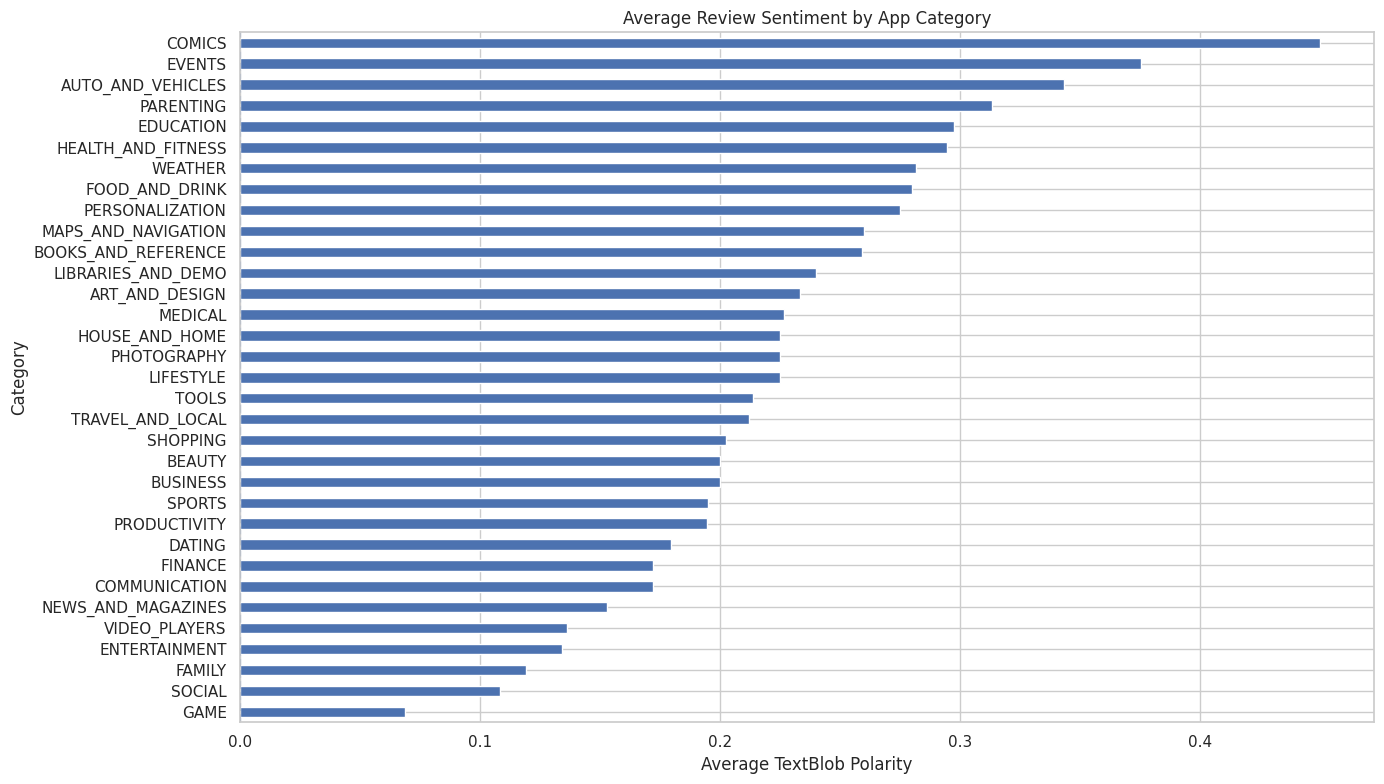

In [38]:
plt.figure(figsize=(14, 8))

sentiment_by_category.sort_values().plot(
    kind="barh"
)

plt.axvline(
    x=0,
    linestyle="--"
)

plt.title("Average Review Sentiment by App Category")
plt.xlabel("Average TextBlob Polarity")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [39]:
category_summary = (
    apps.groupby("Category")
    .agg(
        App_Count=("App", "count"),
        Average_Rating=("Rating", "mean"),
        Total_Installs=("Installs", "sum"),
        Average_Size_MB=("Size_MB", "mean")
    )
    .reset_index()
)

fig = px.scatter(
    category_summary,
    x="App_Count",
    y="Average_Rating",
    size="Total_Installs",
    color="Category",
    hover_name="Category",
    hover_data=[
        "App_Count",
        "Average_Rating",
        "Total_Installs",
        "Average_Size_MB"
    ],
    title="Interactive Google Play Store Category Analysis"
)

fig.show()

In [40]:
# Insight 1: Most saturated categories
top_categories = category_counts.head(3)

# Insight 2: Highest-rated categories
rating_counts = (
    apps.groupby("Category")
    .agg(
        Average_Rating=("Rating", "mean"),
        Rated_App_Count=("Rating", "count")
    )
)

# Exclude categories with very few rated apps
eligible_categories = rating_counts[
    rating_counts["Rated_App_Count"] >= 10
]

top_rated_categories = (
    eligible_categories["Average_Rating"]
    .sort_values(ascending=False)
    .head(3)
)

# Insight 3: Most positive and negative review sentiment
sentiment_summary = (
    reviews_category.groupby("Category")
    .agg(
        Average_Polarity=("Calculated_Polarity", "mean"),
        Review_Count=("Calculated_Polarity", "count")
    )
)

eligible_sentiment = sentiment_summary[
    sentiment_summary["Review_Count"] >= 10
]

most_positive = eligible_sentiment[
    "Average_Polarity"
].idxmax()

most_negative = eligible_sentiment[
    "Average_Polarity"
].idxmin()

print("========== THREE DATA-DRIVEN INSIGHTS ==========")

print("\nINSIGHT 1: MOST SATURATED CATEGORIES")
print(top_categories)

print("\nINSIGHT 2: HIGHEST-RATED CATEGORIES")
print(top_rated_categories.round(2))

print("\nINSIGHT 3: USER SENTIMENT")
print(
    "Most positive category:",
    most_positive,
    "- Average polarity:",
    round(
        eligible_sentiment.loc[
            most_positive, "Average_Polarity"
        ],
        3
    )
)

print(
    "Most negative category:",
    most_negative,
    "- Average polarity:",
    round(
        eligible_sentiment.loc[
            most_negative, "Average_Polarity"
        ],
        3
    )
)

========== THREE DATA-DRIVEN INSIGHTS ==========

INSIGHT 1: MOST SATURATED CATEGORIES
Category
FAMILY    1943
GAME      1121
TOOLS      843
Name: count, dtype: Int64

INSIGHT 2: HIGHEST-RATED CATEGORIES
Category
EVENTS            4.44
EDUCATION         4.38
ART_AND_DESIGN    4.36
Name: Average_Rating, dtype: float64

INSIGHT 3: USER SENTIMENT
Most positive category: COMICS - Average polarity: 0.45
Most negative category: GAME - Average polarity: 0.069


In [41]:
apps.to_csv(
    "cleaned_googleplaystore_apps.csv",
    index=False
)

reviews.to_csv(
    "cleaned_googleplaystore_reviews.csv",
    index=False
)

reviews_category.to_csv(
    "googleplaystore_sentiment_by_category.csv",
    index=False
)

print("All cleaned datasets saved successfully!")

All cleaned datasets saved successfully!


In [42]:
from google.colab import files

files.download("cleaned_googleplaystore_apps.csv")
files.download("cleaned_googleplaystore_reviews.csv")
files.download("googleplaystore_sentiment_by_category.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>